# Routing meltwater over a flexing ice shelf

Fill-spill-merge routes water over a **fixed** surface. On a floating ice shelf that surface is not fixed: the water it collects into lakes is a load. The shelf sags under it, instantly (elastically) and then more over days (by viscous creep). Lake basins deepen, spill points move, and water that would have spilled on may now stay put, or the other way round.

This notebook runs the two models **together in time**: fill-spill-merge (the original algorithm, through the [`fillspillmerge`](https://github.com/jkingslake/fillspillmerge) wrapper) and the viscoelastic plate from this folder. Each moves the other. We then compare the result with routing on a rigid shelf.

Companion notebooks:

* [`lake_drainage_flexure.ipynb`](lake_drainage_flexure.ipynb) drains a single lake.
* [`drainage_reorganisation.ipynb`](drainage_reorganisation.ipynb) combines drainage with this coupling.

## The coupled loop

Each interval $[t_i, t_{i+1}]$ (one day here) has two stages:

1. **Route.** The water already on the surface plus the day's melt is routed by fill-spill-merge over the *current* surface, $s = \text{DEM} - w(t_i)$, where $w$ is positive down. All surface water is redistributed, so lakes can grow, spill, merge or move as the surface changes.
2. **Flex.** The plate is advanced to $t_{i+1}$ under the new load $q = \rho_w g\,d$, in four Crank–Nicolson substeps, with the load changing linearly from the previous routing. This gives $w(t_{i+1})$ and hence the surface for the next routing.

A few assumptions go with this:

* Routing is instantaneous: water reaches its fill-spill-merge equilibrium within a day.
* The two models are coupled explicitly (operator splitting). Section 6 checks that halving the coupling frequency changes little.
* The DEM is the *unloaded* surface at the start of the season: no water and no stored bending.
* Water reaching the edge of the domain (or the ocean) is lost.
* The plate is the one from the drainage notebook: uniform thickness $H = 400$ m on a 128 m grid, with grounded ice held fixed.

All of this is `lake_routing.route_with_flexure`.

## 1. Set-up

In [1]:
import os, time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import hvplot.xarray
import plotstyle as ps
from plotstyle import show_map, hillshade
from viscoelastic_beam import IceShelf
import lake_routing as lr
from lake_routing import (DAY, load_dem, floating_mask, route, find_lakes, ShelfPlate,
                          route_with_flexure, lake_for)
try:
    import pdemtools as pdt          # only needed to download the DEM again
except ImportError:
    pdt = None
ps.apply()
pd.set_option("display.precision", 2)
# The fill-spill-merge wrapper must be importable (see lake_routing.py), e.g.
# os.environ["FILLSPILLMERGE_PATH"] = os.path.expanduser("~/fsm_pywrapper/fillspillmerge")
# set FILLSPILLMERGE_PATH (in the shell, or here) to the folder holding fillspillmerge/ and build/
if "FILLSPILLMERGE_PATH" not in os.environ:
    os.environ["FILLSPILLMERGE_PATH"] = os.path.expanduser("~/Documents/science/meltwater_routing/fsm_pywrapper/fillspillmerge")
lr._import_fsm()
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)



In [2]:
# bounds = [385782, 2041610, 488209, 2160000] # nivlisen
# dem = pdt.load.mosaic(
#     dataset='rema',  # must be `arcticdem` or `rema`
#     resolution=32,        # must be 2, 10, or 32
#     bounds=bounds,        # (xmin, ymin, xmax, ymax) or a shapely geometry
#     chunks = True
# )


# dem.rio.to_raster('Nivlisen_32m_REMA_v2.tif')

DEM_FILE = "../python/notebooks/Nivlisen_32m_REMA_v2.tif"     # not in git (47 MB): recreate with the pdt cell above
dem = load_dem(DEM_FILE, coarsen=10)          # 64 m; the edge ring is an ocean outlet
dem  = dem.sel(x = slice(420000, 470000), y = slice( 2.13e6, 2.06e6,))
z = dem.values.copy()
z[[0, -1], :] = z[:, [0, -1]] = 0.0
dem = dem.copy(data=z)
floating = floating_mask(dem)
area = lr.cell_area(dem)
hs = hillshade(dem)

def grounding_line(ax, mask):
    ax.contour(mask.x / 1e3, mask.y / 1e3, mask.astype(float), levels=[0.5], colors=ps.TENSION, linewidths=1.0)

H = 400.0
print(f"{dem.sizes['y']} x {dem.sizes['x']} routing cells of 64 m; plate H = {H:.0f} m, "
      f"ell = {IceShelf(H=H).ell:.0f} m")

219 x 156 routing cells of 64 m; plate H = 400 m, ell = 873 m


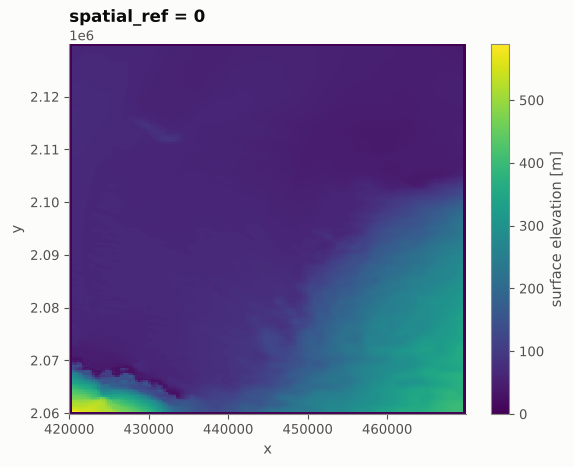

In [3]:


dem.plot()

## 2. A melt season

The season lasts 60 days, releasing 0.5 m of water in every cell in total. The daily rate follows $\sin^2$, peaking mid-season. Another 30 days follow with no melt; the shelf keeps creeping under its lakes during them, so the water keeps moving.

In [4]:
center_x = dem.x.mean().values
center_y = dem.y.mean().values-10000

region_size = 5000
circular_mask = (np.abs(dem.x - center_x)**2 + (np.abs(dem.y - center_y)**2) < region_size**2).transpose(*dem.dims)

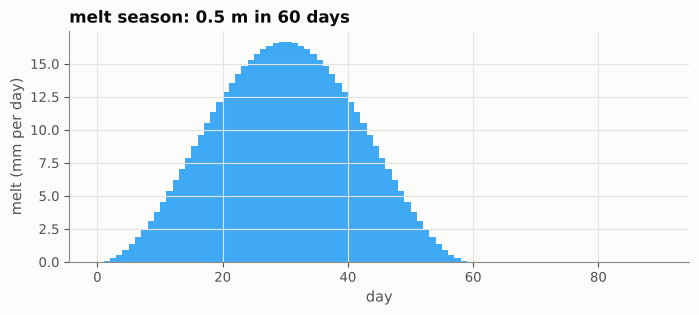

In [5]:
MELT, SEASON, AFTER = 0.5, 60, 30
days = np.arange(SEASON + AFTER + 1)
rate = np.where(days[:-1] < SEASON, np.sin(np.pi * (days[:-1] + 0.5) / SEASON) ** 2, 0.0)
melt_per_day = MELT * rate / rate.sum()                  # m of water released per cell each day
melt = lambda i: xr.full_like(dem, melt_per_day[i])*circular_mask
t = days * DAY
STORE = list(range(0, days.size, 2))                    # keep maps every 2 days

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(days[:-1] + 0.5, 1e3 * melt_per_day, width=1.0, color=ps.WATER)
ax.set(xlabel="day", ylabel="melt (mm per day)", title=f"melt season: {MELT} m in {SEASON} days");

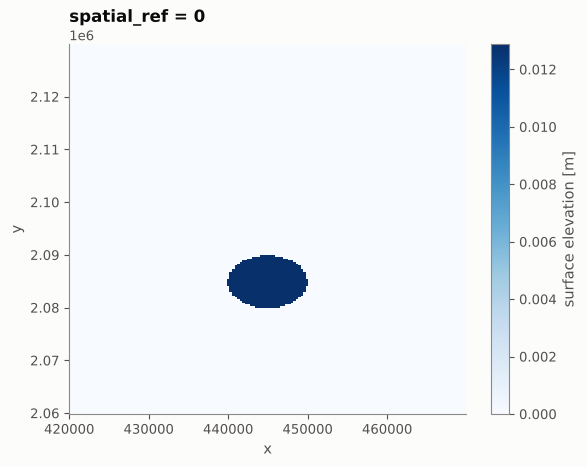

In [6]:
melt(20).plot(cmap="Blues")

In [7]:
# fill out a xarray the same shape as the DEM, with melt values for each day
melt_xr = xr.concat([melt(i) for i in range(days.size-1)], dim="time")

In [8]:
runs = {}

runs["rigid"] = route_with_flexure(dem, melt, t, plate=None, store=STORE, verbose=True)


  day   10.0: stored      1.1 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   20.0: stored      7.7 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   30.0: stored     19.6 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   40.0: stored     31.6 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   50.0: stored     38.1 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   60.0: stored     39.2 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   70.0: stored     39.2 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   80.0: stored     39.2 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   90.0: stored     39.2 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


In [9]:
coarse = runs["rigid"].coarsen(x=1, y=1, boundary = 'trim').mean()

coarse.surface.hvplot(x='x', y='y', cmap='gist_earth',aspect='equal', width = 500)\
    * coarse.water_depth.where(coarse>0).hvplot(x = 'x',y='y', aspect='equal', clim = (0,1))



:DynamicMap   [step_time,time]
   :Overlay
      .Image.I  :Image   [x,y]   (deformed surface (dem - w))
      .Image.II :Image   [x,y]   (water depth)

## 3. Three shelves

All three runs use the same melt; only the shelf differs.

| run | shelf |
|---|---|
| `rigid` | does not move: plain fill-spill-merge, one day at a time |
| `elastic` | sags instantly, never creeps ($\eta = 10^{25}$ Pa s) |
| `viscoelastic` | sags instantly, then creeps ($\eta = 10^{14}$ Pa s, relaxation times ≈ 3 and 5 days) |

Each coupled day costs about one fill-spill-merge call (≈ 0.5 s for 786,000 cells) plus four plate steps (≈ 0.05 s each).

In [10]:
t0 = time.perf_counter()
for name, eta in [("elastic", 1e25), ("viscoelastic", 1e14)]:
    t0 = time.perf_counter()
    plate = ShelfPlate(dem, floating, IceShelf(H=H, eta=eta), coarsen=2).start()
    runs[name] = route_with_flexure(dem, melt, t, plate=plate, store=STORE, verbose=True, substeps=16)
    print(f"{name}: {time.perf_counter() - t0:.0f} s")
coupled = runs["viscoelastic"]
coupled

  day   10.0: stored      1.1 Mm3, lost      0.0 Mm3, max deflection   0.02 m


  day   20.0: stored      7.7 Mm3, lost     -0.0 Mm3, max deflection   0.49 m


  day   30.0: stored     19.6 Mm3, lost     -0.0 Mm3, max deflection   1.12 m


  day   40.0: stored     31.6 Mm3, lost     -0.0 Mm3, max deflection   1.70 m


  day   50.0: stored     38.1 Mm3, lost     -0.0 Mm3, max deflection   2.02 m


  day   60.0: stored     39.2 Mm3, lost     -0.0 Mm3, max deflection   2.07 m


... (9 outputs left out)

  day   70.0: stored     39.2 Mm3, lost     -0.0 Mm3, max deflection   3.93 m


  day   80.0: stored     39.2 Mm3, lost     -0.0 Mm3, max deflection   4.08 m


  day   90.0: stored     39.2 Mm3, lost     -0.0 Mm3, max deflection   4.20 m
viscoelastic: 5 s


<xarray.Dataset> Size: 19MB
Dimensions:         (time: 46, y: 219, x: 156, step_time: 91)
Coordinates:
  * time            (time) float64 368B 0.0 1.728e+05 ... 7.603e+06 7.776e+06
    time_days       (time) float64 368B 0.0 2.0 4.0 6.0 ... 84.0 86.0 88.0 90.0
  * y               (y) float64 2kB 2.13e+06 2.129e+06 ... 2.06e+06 2.06e+06
  * x               (x) float64 1kB 4.202e+05 4.205e+05 ... 4.694e+05 4.698e+05
  * step_time       (step_time) float64 728B 0.0 8.64e+04 ... 7.69e+06 7.776e+06
    step_time_days  (step_time) float64 728B 0.0 1.0 2.0 3.0 ... 88.0 89.0 90.0
    spatial_ref     int64 8B 0
Data variables:
    water_depth     (time, y, x) float32 6MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    deflection      (time, y, x) float32 6MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    surface         (time, y, x) float32 6MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    melt_added      (step_time) float64 728B 0.0 895.8 ... 3.922e+07 3.922e+07
    water_stored    (step_time) float64 728B 0.0 895.8 ... 3.922e+07 3.922e+07
    water_lost      (step_time) float64 728B 0.0 1.264e-09 ... -2.464 -2.464
    max_deflection  (step_time) float64 728B 0.0 2.594e-05 ... 4.194 4.205
Attributes:
    coupled:      1
    substeps:     16
    ocean_level:  0.0
    shelf_H:      400.0
    shelf_E:      1000000000.0
    shelf_eta:    100000000000000.0
    shelf_nu:     0.3
    shelf_nu_v:   0.5
    plate_dx:     640.0

In [11]:
coarse = runs["viscoelastic"].coarsen(x=1, y=1, boundary = 'trim').mean()

coarse.surface.hvplot(x='x', y='y', cmap='gist_earth',aspect='equal', width = 500)\
    * coarse.water_depth.where(coarse>0).hvplot(x = 'x',y='y', aspect='equal', clim = (0,1))\
    + coarse.deflection.hvplot(x='x',y='y', aspect='equal', width = 500, cmap='RdBu_r', clim=(-1,1))


:Layout
   .DynamicMap.I  :DynamicMap   [step_time,time]
      :Overlay
         .Image.I  :Image   [x,y]   (deformed surface (dem - w))
         .Image.II :Image   [x,y]   (water depth)
   .DynamicMap.II :DynamicMap   [time]
      :Image   [x,y]   (deflection (+ down))

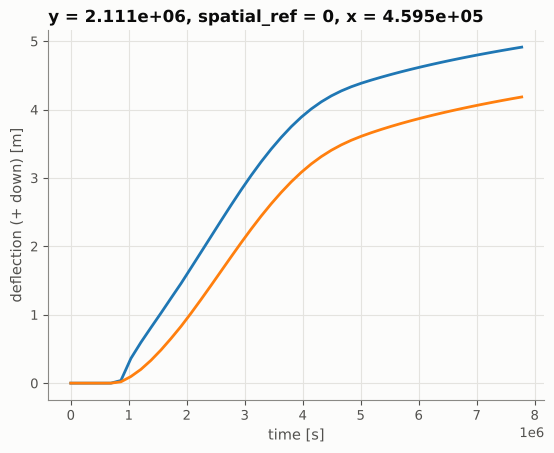

In [12]:
w_end = coarse.water_depth.isel(time=-1)
pt = w_end.isel(w_end.argmax(dim=["y", "x"]))
ts_at_max = coarse.sel(x=pt.x.item(), y=pt.y.item(), method="nearest")
ts_at_max.water_depth.plot()
# ts_at_max.surface.plot()
ts_at_max.deflection.plot()


## 4. The water budget

The left panel shows water held on the surface; the right panel shows cumulative water lost at the edges. Every run conserves water to round-off: melt added = stored + lost.

        rigid: stored     39 Mm³ at day 60,     39 Mm³ at day 90; lost     -0 Mm³ (budget error 4e-16)
      elastic: stored     39 Mm³ at day 60,     39 Mm³ at day 90; lost     -0 Mm³ (budget error 8e-16)
 viscoelastic: stored     39 Mm³ at day 60,     39 Mm³ at day 90; lost     -0 Mm³ (budget error 2e-16)


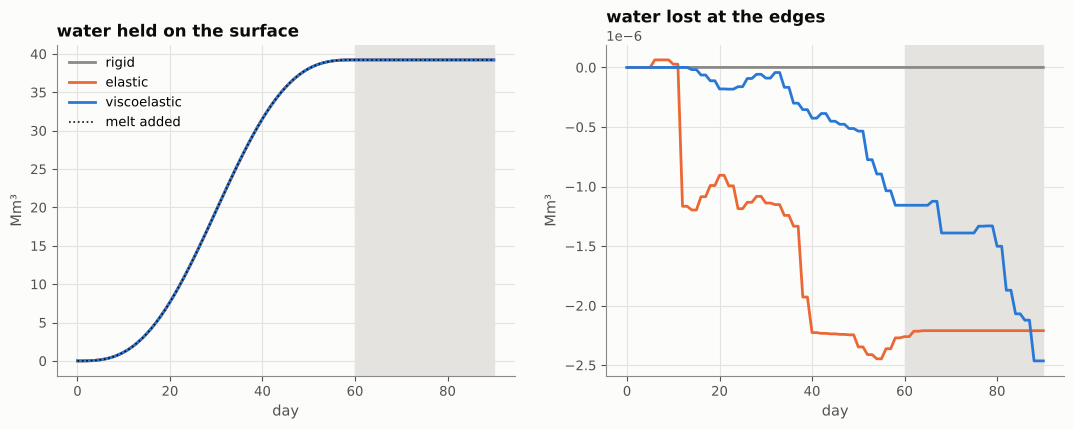

In [13]:
cols = {"rigid": ps.MUTED, "elastic": ps.ELASTIC, "viscoelastic": ps.VISCO}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for name, r in runs.items():
    ax[0].plot(r.step_time_days, r.water_stored / 1e6, color=cols[name], label=name)
    ax[1].plot(r.step_time_days, r.water_lost / 1e6, color=cols[name], label=name)
    err = float(np.max(np.abs(r.water_stored + r.water_lost - r.melt_added)) / r.melt_added[-1])
    print(f"{name:>13}: stored {float(r.water_stored[SEASON]) / 1e6:6.0f} Mm³ at day {SEASON}, "
          f"{float(r.water_stored[-1]) / 1e6:6.0f} Mm³ at day {days[-1]}; lost {float(r.water_lost[-1]) / 1e6:6.0f} Mm³ "
          f"(budget error {err:.0e})")
ax[0].plot(runs["rigid"].step_time_days, runs["rigid"].melt_added / 1e6, color=ps.INK, ls=":", lw=1.2, label="melt added")
for a, title in zip(ax, ["water held on the surface", "water lost at the edges"]):
    a.axvspan(SEASON, days[-1], color=ps.GRID, zorder=0)
    a.set(xlabel="day", ylabel="Mm³", title=title)
ax[0].legend();

## 5. Where the water is

The maps compare the end of the melt season on the rigid and the viscoelastic shelf. The third panel is the difference in water depth between them; the fourth is the viscoelastic shelf's deflection.

largest deflection 3.7 m; water depth changes from -1.2 to 2.4 m


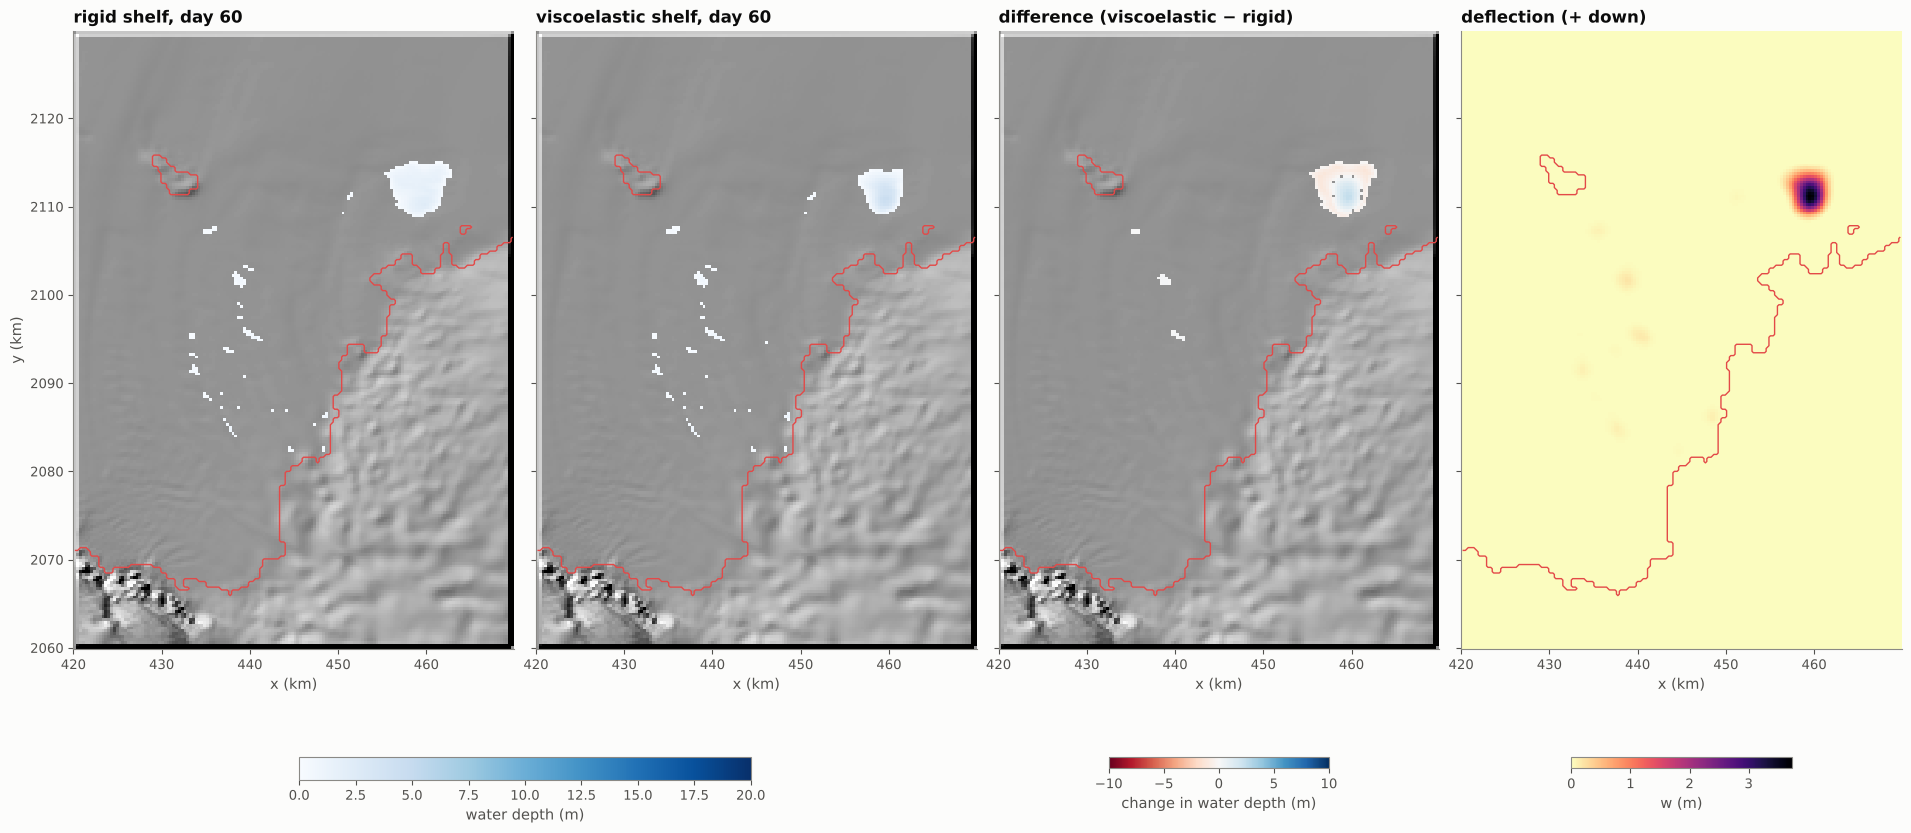

In [14]:
day = SEASON
R, C = runs["rigid"].sel(time_days=day), coupled.sel(time_days=day)
diff = C.water_depth - R.water_depth
fig, ax = plt.subplots(1, 4, figsize=(19, 13), sharey=True, constrained_layout=True)
for a, d_, ttl in [(ax[0], R.water_depth, "rigid shelf"), (ax[1], C.water_depth, "viscoelastic shelf")]:
    show_map(a, hs, f"{ttl}, day {day}", cmap="gray", vmin=0, vmax=1)
    im = show_map(a, d_.where(d_ > 0.05), cmap="Blues", vmin=0, vmax=20)
fig.colorbar(im, ax=ax[:2], shrink=0.5, label="water depth (m)", location="bottom")
show_map(ax[2], hs, "difference (viscoelastic − rigid)", cmap="gray", vmin=0, vmax=1)
im = show_map(ax[2], diff.where(abs(diff) > 0.05), cmap="RdBu", vmin=-10, vmax=10)
fig.colorbar(im, ax=ax[2], shrink=0.5, label="change in water depth (m)", location="bottom")
im = show_map(ax[3], C.deflection, "deflection (+ down)", cmap="magma_r", vmin=0)
fig.colorbar(im, ax=ax[3], shrink=0.5, label="w (m)", location="bottom")
for a in ax:
    grounding_line(a, floating)
for a in ax[1:]:
    a.set_ylabel("")
print(f"largest deflection {float(C.deflection.max()):.1f} m; water depth changes from {float(diff.min()):.1f} "
      f"to {float(diff.max()):.1f} m")

### Lake by lake

Each of the largest lakes on the viscoelastic shelf is compared with the water the rigid shelf holds in lakes overlapping it. The table also gives how far the ice beneath each lake has sagged.

In [15]:
lab_c, lakes_c = find_lakes(C.water_depth, floating)
lab_r, lakes_r = find_lakes(R.water_depth, floating)
rows = []
for L in lakes_c.lake.values[:10]:
    fp = lab_c == L
    rigid_labels = lake_for(lab_r, fp)
    v_r = float(lakes_r.volume.sel(lake=rigid_labels).sum()) if rigid_labels.size else 0.0
    rows.append(dict(lake=L, volume_coupled_Mm3=float(lakes_c.volume.sel(lake=L)) / 1e6,
                     volume_rigid_Mm3=v_r / 1e6,
                     max_depth_coupled=float(lakes_c.max_depth.sel(lake=L)),
                     max_sag_m=float(C.deflection.where(fp).max()),
                     floating_fraction=float(lakes_c.floating_fraction.sel(lake=L))))
by_lake = pd.DataFrame(rows).set_index("lake")
by_lake["change_%"] = 100 * (by_lake.volume_coupled_Mm3 / by_lake.volume_rigid_Mm3 - 1)
by_lake

,volume_coupled_Mm3,volume_rigid_Mm3,max_depth_coupled,max_sag_m,floating_fraction,change_%
lake,,,,,,
1,36.47,36.88,4.43,3.72,1.0,-1.11
12,0.60,0.46,0.67,0.19,1.0,31.79
20,0.50,0.40,0.82,0.15,1.0,25.01
25,0.23,0.21,0.37,0.09,1.0,11.86
7,0.23,0.17,0.31,0.09,1.0,37.75
41,0.22,0.21,0.97,0.11,1.0,7.83
45,0.14,0.13,0.80,0.10,1.0,6.53
3,0.10,0.08,0.34,0.05,1.0,16.84
22,0.08,0.07,0.30,0.04,1.0,12.69


### Why the lakes hold more: basins sink under their own water

Under a broad lake, the shelf sags by close to $\rho_w d/\rho_{sw} \approx 0.97\,d$ once it has relaxed. The scatter shows sag against water depth on floating ice at the end of the run, after 30 days with no melt; the dashed line is that isostatic value.

The basin floor drops, but the rim, where there is little water, does not, so the basin can hold more before it spills. Narrow lakes and lakes against the grounding line sag less: the plate's stiffness holds them up.

median sag / (0.97 d): 0.94


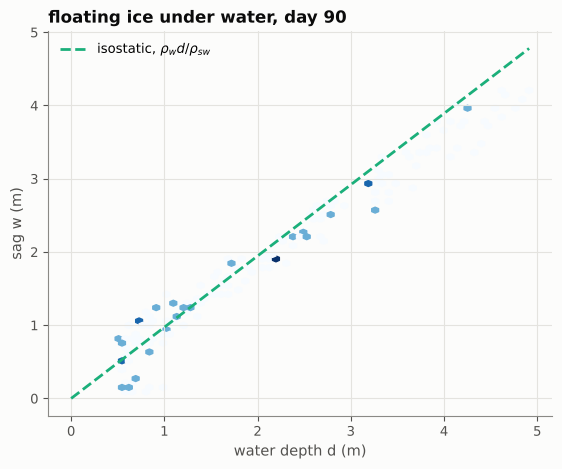

In [16]:
E = coupled.isel(time=-1)
sel = (E.water_depth > 0.5) & floating
dd, ww = E.water_depth.values[sel.values], E.deflection.values[sel.values]
shelf = IceShelf(H=H)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.hexbin(dd, ww, gridsize=60, bins="log", cmap="Blues", mincnt=1)
x_ = np.linspace(0, dd.max(), 2)
ax.plot(x_, shelf.rho_w / shelf.rho_sw * x_, ls="--", color=ps.ISO, label=r"isostatic, $\rho_w d/\rho_{sw}$")
ax.set(xlabel="water depth d (m)", ylabel="sag w (m)", title=f"floating ice under water, day {days[-1]}")
ax.legend(loc="upper left")
print(f"median sag / (0.97 d): {np.median(ww / (shelf.rho_w / shelf.rho_sw * dd)):.2f}")

### The grounding-line lake through the season

The largest lake sits against the grounding line. Below, a west–east profile through it is shown at three times, for the rigid and the viscoelastic shelf. The deformed surface is drawn as a line; water is shaded.

        rigid, day 90:    37 Mm³ over 34.1 km², max depth  2.4 m, water level  42.5 m
 viscoelastic, day 90:    36 Mm³ over 19.8 km², max depth  4.9 m, water level  41.1 m


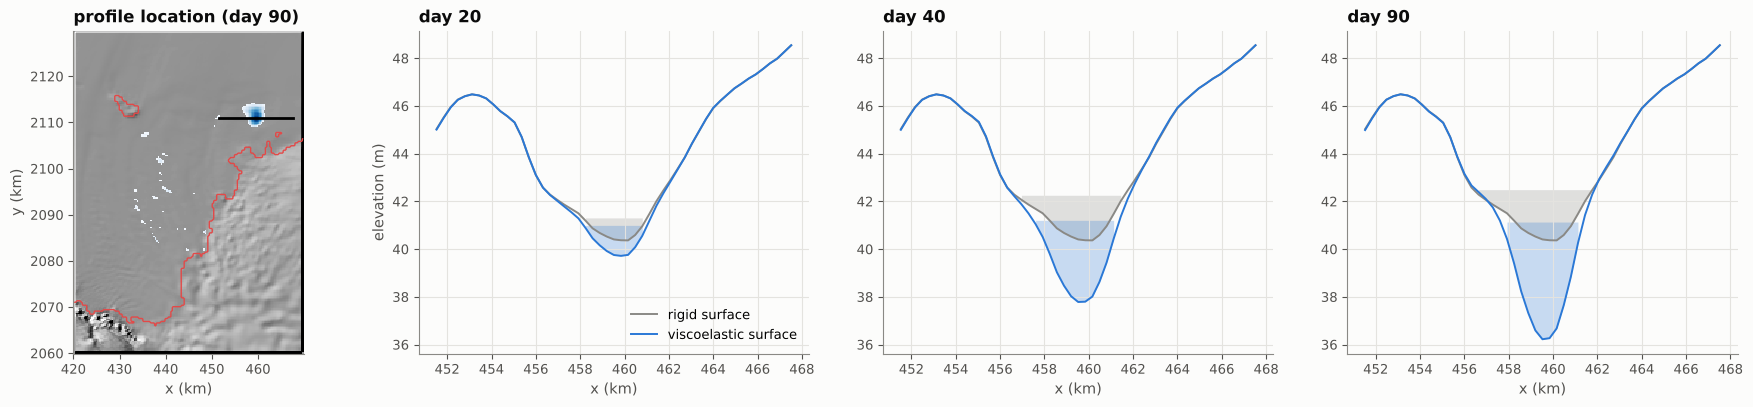

In [17]:
# profile line: west–east through the deepest water on the viscoelastic shelf at the end of the run
E = coupled.isel(time=-1)
yc, xc = E.water_depth.where(floating).stack(p=("y", "x")).idxmax("p").item()
XS = slice(xc - 8e3, xc + 8e3)

fig, ax = plt.subplots(1, 4, figsize=(22, 4.2), gridspec_kw=dict(width_ratios=[0.8, 1, 1, 1]))
# map of where the profile is
show_map(ax[0], hs, f"profile location (day {days[-1]})", cmap="gray", vmin=0, vmax=1)
show_map(ax[0], E.water_depth.where(E.water_depth > 0.05), cmap="Blues", vmin=0, vmax=5)
grounding_line(ax[0], floating)
ax[0].plot([XS.start / 1e3, XS.stop / 1e3], [yc / 1e3] * 2, color="k", lw=2)

# profiles through time
for a in ax[2:]:
    a.sharey(ax[1])
for a, d_ in zip(ax[1:], [20, 40, 90]):
    for name, c in [("rigid", ps.MUTED), ("viscoelastic", ps.VISCO)]:
        s_ = runs[name].sel(time_days=d_).sel(y=yc, method="nearest").sel(x=XS)
        a.fill_between(s_.x / 1e3, s_.surface, s_.surface + s_.water_depth, where=s_.water_depth > 0,
                       color=c, alpha=0.25, lw=0)
        a.plot(s_.x / 1e3, s_.surface, color=c, lw=1.4, label=f"{name} surface")
    a.set(title=f"day {d_}", xlabel="x (km)")
ax[1].set_ylabel("elevation (m)")
ax[1].legend(loc="lower right")

for name in ("rigid", "viscoelastic"):
    e = runs[name].isel(time=-1)
    lab_e, lakes_e = find_lakes(e.water_depth, floating)
    Le = int(lakes_e.lake[0])                            # the largest lake
    level = float((e.surface + e.water_depth).where(lab_e == Le).median())
    print(f"{name:>13}, day {days[-1]}: {float(lakes_e.volume[0]) / 1e6:5.0f} Mm³ over {float(lakes_e.area[0]) / 1e6:4.1f} km², "
          f"max depth {float(lakes_e.max_depth[0]):4.1f} m, water level {level:5.1f} m")

### Two big seasons: does flexure stop the depression overflowing?

Each season puts 10% more melt than the big depression can hold on a rigid shelf, so on the rigid shelf it fills and spills in season 1. A second, identical season follows. The question is whether the room that sagging adds lets the viscoelastic shelf hold the water instead. Water spilling out of this depression leaves the domain, so `water_lost` measures the overflow.

depression capacity 606 Mm³ over 196 km²; melt 3.9 m per season = 303 Mm³


  day   10.0: stored      8.7 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   20.0: stored     59.3 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   30.0: stored    151.6 Mm3, lost     -0.0 Mm3, max deflection   0.00 m


  day   40.0: stored    243.9 Mm3, lost      0.0 Mm3, max deflection   0.00 m


  day   50.0: stored    294.5 Mm3, lost      0.0 Mm3, max deflection   0.00 m


... (27 outputs left out)

  day  150.0: stored    606.4 Mm3, lost     -0.0 Mm3, max deflection  25.41 m


  day  160.0: stored    606.4 Mm3, lost     -0.0 Mm3, max deflection  25.80 m


  day  170.0: stored    606.4 Mm3, lost     -0.0 Mm3, max deflection  26.16 m


  day  180.0: stored    606.4 Mm3, lost     -0.0 Mm3, max deflection  26.48 m
        rigid, end of season 1 (day 90):   301 Mm³ in the depression,     0 Mm³ spilled off the shelf
        rigid, end of season 2 (day 180):   604 Mm³ in the depression,     0 Mm³ spilled off the shelf
 viscoelastic, end of season 1 (day 90):   301 Mm³ in the depression,     0 Mm³ spilled off the shelf
 viscoelastic, end of season 2 (day 180):   604 Mm³ in the depression,    -0 Mm³ spilled off the shelf


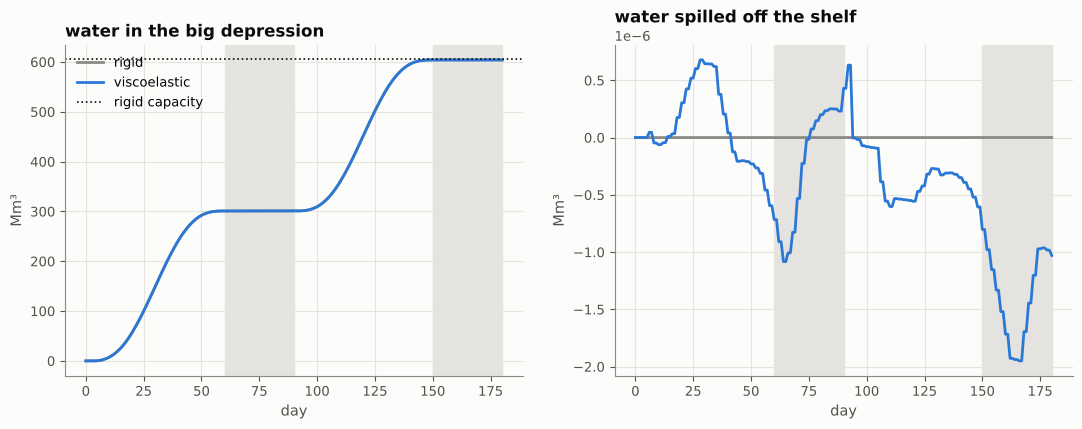

In [18]:
# Capacity of the big depression on the rigid shelf: route far more melt than it can hold
full = route(dem, 20.0 * circular_mask)
lab_f, lakes_f = find_lakes(full, floating)
basin = lab_f == int(lakes_f.lake[0])                    # footprint of the full depression
CAP = float(lakes_f.volume[0])
A_circ = float(circular_mask.sum()) * area
# melt per season that just overfills the rigid depression (5% more than its capacity)
MELT2 = 0.5 * CAP / A_circ
days2 = np.arange(2 * (SEASON + AFTER) + 1)
dd_ = days2[:-1] % (SEASON + AFTER)
rate2 = np.where(dd_ < SEASON, np.sin(np.pi * (dd_ + 0.5) / SEASON) ** 2, 0.0)
melt_per_day2 = MELT2 * rate2 / rate.sum()               # same seasonal shape, MELT2 per season
melt_big = lambda i: xr.full_like(dem, melt_per_day2[i]) * circular_mask
t_2 = days2 * DAY
STORE2 = sorted(set(range(0, days2.size, 2)) | {SEASON + AFTER, days2.size - 1})  # keep maps every 2 days (plus season ends)
print(f"depression capacity {CAP / 1e6:.0f} Mm³ over {float(basin.sum()) * area / 1e6:.0f} km²; "
      f"melt {MELT2:.1f} m per season = {MELT2 * A_circ / 1e6:.0f} Mm³")

runs2 = {"rigid": route_with_flexure(dem, melt_big, t_2, plate=None, store=STORE2,
                                     track={"basin": basin}, verbose = True)}
plate = ShelfPlate(dem, floating, IceShelf(H=H, eta=1e15), coarsen=2).start()
runs2["viscoelastic"] = route_with_flexure(dem, melt_big, t_2, plate=plate, substeps=16,
                                           store=STORE2, track={"basin": basin}, verbose = True)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for name, c in [("rigid", ps.MUTED), ("viscoelastic", ps.VISCO)]:
    r = runs2[name]
    ax[0].plot(r.step_time_days, r.tracked_volume.sel(region="basin") / 1e6, color=c, label=name)
    ax[1].plot(r.step_time_days, r.water_lost / 1e6, color=c, label=name)
    for s in (1, 2):
        d_end = s * (SEASON + AFTER)
        print(f"{name:>13}, end of season {s} (day {d_end}): {float(r.tracked_volume.sel(region='basin', step_time_days=d_end)) / 1e6:5.0f} Mm³ in the depression, "
              f"{float(r.water_lost.sel(step_time_days=d_end)) / 1e6:5.0f} Mm³ spilled off the shelf")
ax[0].axhline(CAP / 1e6, color=ps.INK, ls=":", lw=1.2, label="rigid capacity")
for a, title in zip(ax, ["water in the big depression", "water spilled off the shelf"]):
    for s in (0, 1):
        a.axvspan(s * (SEASON + AFTER) + SEASON, (s + 1) * (SEASON + AFTER), color=ps.GRID, zorder=0)
    a.set(xlabel="day", ylabel="Mm³", title=title)
ax[0].legend();

big lake 196 km², catchment 2393 km² (100% of the melt area drains to it)
        rigid, day  60: big lake   301 Mm³, area feeding the big lake     2 Mm³, rest of the domain     0 Mm³
        rigid, day  90: big lake   301 Mm³, area feeding the big lake     2 Mm³, rest of the domain     0 Mm³
        rigid, day 150: big lake   604 Mm³, area feeding the big lake     2 Mm³, rest of the domain     0 Mm³
        rigid, day 180: big lake   604 Mm³, area feeding the big lake     2 Mm³, rest of the domain     0 Mm³
 viscoelastic, day  60: big lake   301 Mm³, area feeding the big lake     2 Mm³, rest of the domain     0 Mm³
 viscoelastic, day  90: big lake   301 Mm³, area feeding the big lake     2 Mm³, rest of the domain     0 Mm³
 viscoelastic, day 150: big lake   604 Mm³, area feeding the big lake     2 Mm³, rest of the domain     0 Mm³
 viscoelastic, day 180: big lake   604 Mm³, area feeding the big lake     2 Mm³, rest of the domain     0 Mm³


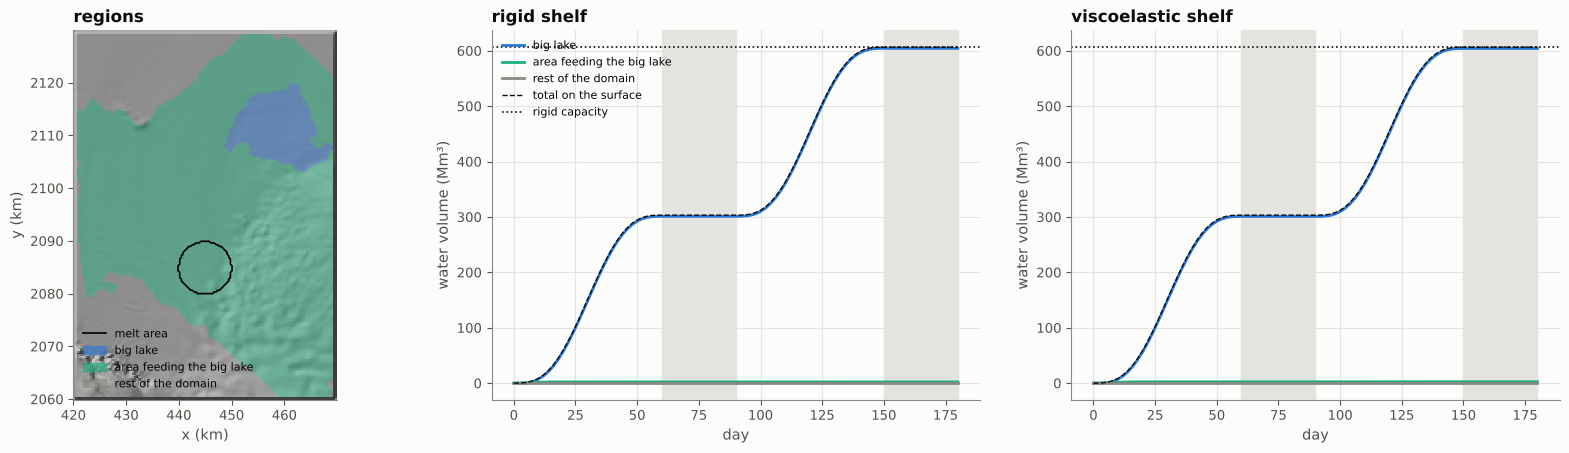

In [19]:
# Water volume through time in the big lake, in the area that feeds it, and everywhere else
from matplotlib.colors import ListedColormap
from lake_routing import drainage_basins

# catchment: every cell whose water ends up in the big depression once smaller depressions on the
# way have filled and spilled (priority flood on the undeformed DEM, with the depression as the only lake)
catchment = drainage_basins(dem, basin.astype(int)) == 1
regions = {"big lake": basin,
           "area feeding the big lake": catchment & ~basin,
           "rest of the domain": ~catchment}
reg_cols = {"big lake": ps.VISCO, "area feeding the big lake": ps.ISO, "rest of the domain": ps.MUTED}
print(f"big lake {float(basin.sum()) * area / 1e6:.0f} km², catchment {float(catchment.sum()) * area / 1e6:.0f} km² "
      f"({float((catchment & circular_mask).sum()) / float(circular_mask.sum()):.0%} of the melt area drains to it)")

def region_volumes(r):
    """Water volume (m³) inside each region at every stored time."""
    return xr.concat([(r.water_depth.where(m).sum(("y", "x")) * area).expand_dims(region=[k])
                      for k, m in regions.items()], dim="region")

vols2 = {name: region_volumes(r) for name, r in runs2.items()}

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8), gridspec_kw=dict(width_ratios=[0.8, 1, 1]))
# map of the regions
show_map(ax[0], hs, "regions", cmap="gray", vmin=0, vmax=1)
reg_id = xr.full_like(dem, np.nan, dtype=float)
for k, (name, m) in enumerate(regions.items()):
    reg_id = reg_id.where(~m, k)
show_map(ax[0], reg_id, cmap=ListedColormap(list(reg_cols.values())), vmin=-0.5, vmax=2.5, alpha=0.45)
ax[0].contour(dem.x / 1e3, dem.y / 1e3, circular_mask.astype(float), levels=[0.5], colors="k", linewidths=1.2)
ax[0].plot([], [], color="k", lw=1.2, label="melt area")
for name, c in reg_cols.items():
    ax[0].fill_between([], [], color=c, alpha=0.6, label=name)
ax[0].legend(loc="lower left", fontsize=8)

# time series, one panel per shelf
for a, name in zip(ax[1:], ["rigid", "viscoelastic"]):
    v = vols2[name]
    for reg, c in reg_cols.items():
        a.plot(v.time_days, v.sel(region=reg) / 1e6, color=c, label=reg)
    a.plot(v.time_days, v.sum("region") / 1e6, color=ps.INK, lw=1, ls="--", label="total on the surface")
    a.axhline(CAP / 1e6, color=ps.INK, ls=":", lw=1.2, label="rigid capacity")
    for s in (0, 1):
        a.axvspan(s * (SEASON + AFTER) + SEASON, (s + 1) * (SEASON + AFTER), color=ps.GRID, zorder=0)
    a.set(xlabel="day", ylabel="water volume (Mm³)", title=f"{name} shelf")
ax[2].sharey(ax[1])
ax[1].legend(loc="upper left", fontsize=8)

for name, v in vols2.items():
    for d_ in (SEASON, SEASON + AFTER, 2 * SEASON + AFTER, days2[-1]):
        print(f"{name:>13}, day {d_:3d}: " + ", ".join(
            f"{reg} {float(v.sel(region=reg).sel(time=d_ * DAY, method='nearest')) / 1e6:5.0f} Mm³" for reg in regions))


In [20]:
hs

<xarray.DataArray 'dem' (y: 219, x: 156)> Size: 273kB
array([[0.57357644, 0.77528753, 0.77556354, ..., 0.81010509, 0.81026885,
        0.57357644],
       [0.77528753, 0.99996499, 0.8139719 , ..., 0.79055607, 0.43071521,
        0.        ],
       [0.77515558, 0.81672425, 0.57404231, ..., 0.58218218, 0.17984041,
        0.        ],
       ...,
       [0.61088958, 0.68929001, 0.71606092, ..., 0.55577545, 0.        ,
        0.        ],
       [0.60950307, 0.06347557, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.57357644, 0.        , 0.        , ..., 0.        , 0.        ,
        0.57357644]], shape=(219, 156))
Coordinates:
  * y            (y) float64 2kB 2.13e+06 2.129e+06 ... 2.06e+06 2.06e+06
  * x            (x) float64 1kB 4.202e+05 4.205e+05 ... 4.694e+05 4.698e+05
    spatial_ref  int64 8B 0
Attributes:
    units:      m
    long_name:  surface elevation
    source:     ../python/notebooks/Nivlisen_32m_REMA_v2.tif

        rigid, day 90:   604 Mm³ over 195.4 km², max depth  8.0 m, water level  47.6 m
 viscoelastic, day 90:   604 Mm³ over 54.7 km², max depth 28.1 m, water level  42.5 m


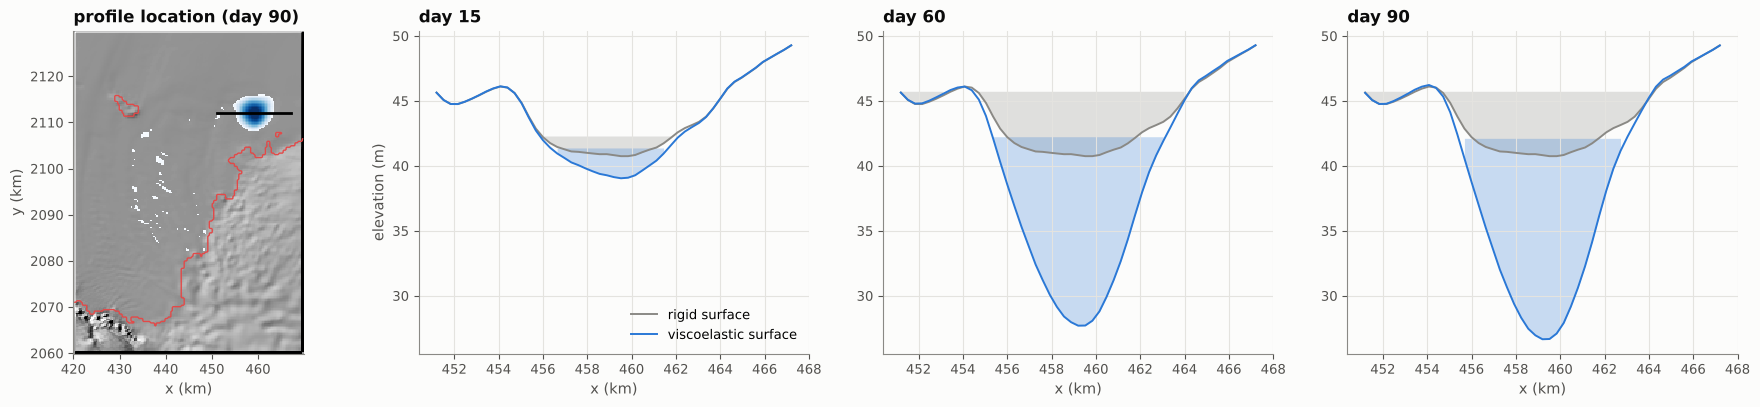

In [21]:
# profile line: west–east through the deepest water on the viscoelastic shelf at the end of the run
E = runs2['viscoelastic'].isel(time=-1)
yc, xc = E.water_depth.where(floating).stack(p=("y", "x")).idxmax("p").item()
XS = slice(xc - 8e3, xc + 8e3)

fig, ax = plt.subplots(1, 4, figsize=(22, 4.2), gridspec_kw=dict(width_ratios=[0.8, 1, 1, 1]))
# map of where the profile is
show_map(ax[0], hs, f"profile location (day {days[-1]})", cmap="gray", vmin=0, vmax=1)
show_map(ax[0], E.water_depth.where(E.water_depth > 0.0), cmap="Blues", vmin=0, vmax=25)
grounding_line(ax[0], floating)
ax[0].plot([XS.start / 1e3, XS.stop / 1e3], [yc / 1e3] * 2, color="k", lw=2)

# profiles through time
for a in ax[2:]:
    a.sharey(ax[1])
for a, d_ in zip(ax[1:], [15, 60, 90]):
    for name, c in [("rigid", ps.MUTED), ("viscoelastic", ps.VISCO)]:
        s_ = runs2[name].sel(time_days=d_,method="nearest").sel(y=yc, method="nearest").sel(x=XS)
        a.fill_between(s_.x / 1e3, s_.surface, s_.surface + s_.water_depth, where=s_.water_depth > 0,
                       color=c, alpha=0.25, lw=0)
        a.plot(s_.x / 1e3, s_.surface, color=c, lw=1.4, label=f"{name} surface")
    a.set(title=f"day {d_}", xlabel="x (km)")
ax[1].set_ylabel("elevation (m)")
ax[1].legend(loc="lower right")

for name in ("rigid", "viscoelastic"):
    e = runs2[name].isel(time=-1)
    lab_e, lakes_e = find_lakes(e.water_depth, floating)
    Le = int(lakes_e.lake[0])                            # the largest lake
    level = float((e.surface + e.water_depth).where(lab_e == Le).median())
    print(f"{name:>13}, day {days[-1]}: {float(lakes_e.volume[0]) / 1e6:5.0f} Mm³ over {float(lakes_e.area[0]) / 1e6:4.1f} km², "
          f"max depth {float(lakes_e.max_depth[0]):4.1f} m, water level {level:5.1f} m")

largest deflection 13.1 m; water depth changes from -6.1 to 9.7 m


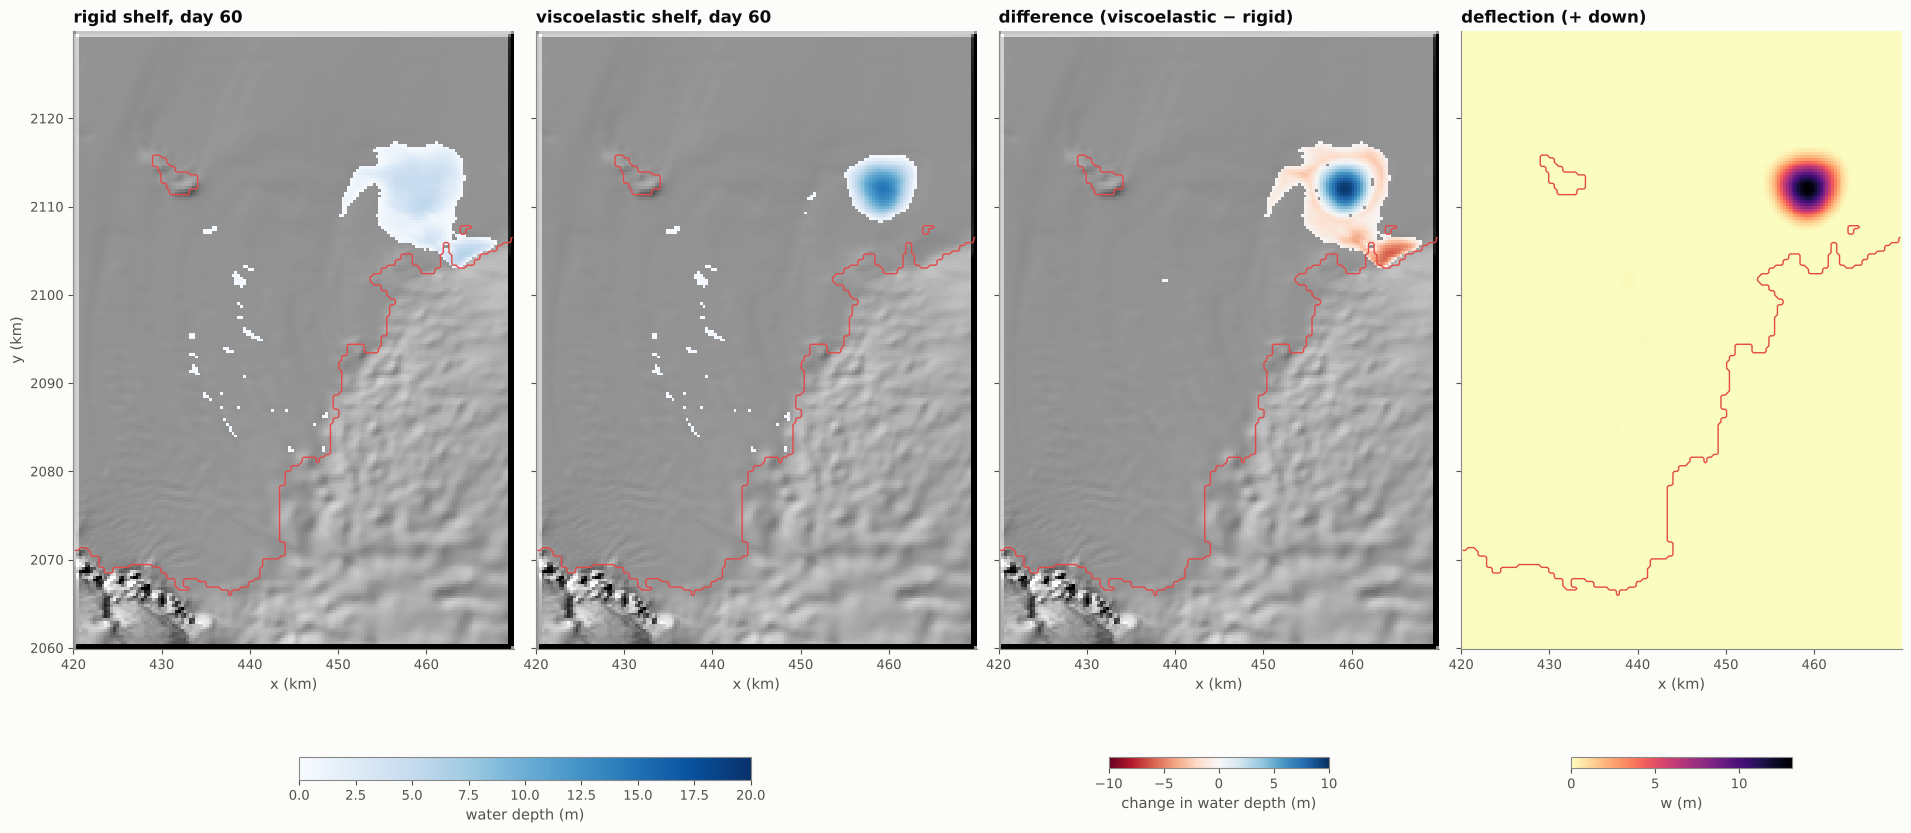

In [22]:
day = SEASON
R, C = runs2["rigid"].sel(time_days=day), runs2['viscoelastic'].sel(time_days=day)
diff = C.water_depth - R.water_depth
fig, ax = plt.subplots(1, 4, figsize=(19, 13), sharey=True, constrained_layout=True)
for a, d_, ttl in [(ax[0], R.water_depth, "rigid shelf"), (ax[1], C.water_depth, "viscoelastic shelf")]:
    show_map(a, hs, f"{ttl}, day {day}", cmap="gray", vmin=0, vmax=1)
    im = show_map(a, d_.where(d_ > 0.05), cmap="Blues", vmin=0, vmax=20)
fig.colorbar(im, ax=ax[:2], shrink=0.5, label="water depth (m)", location="bottom")
show_map(ax[2], hs, "difference (viscoelastic − rigid)", cmap="gray", vmin=0, vmax=1)
im = show_map(ax[2], diff.where(abs(diff) > 0.05), cmap="RdBu", vmin=-10, vmax=10)
fig.colorbar(im, ax=ax[2], shrink=0.5, label="change in water depth (m)", location="bottom")
im = show_map(ax[3], C.deflection, "deflection (+ down)", cmap="magma_r", vmin=0)
fig.colorbar(im, ax=ax[3], shrink=0.5, label="w (m)", location="bottom")
for a in ax:
    grounding_line(a, floating)
for a in ax[1:]:
    a.set_ylabel("")
print(f"largest deflection {float(C.deflection.max()):.1f} m; water depth changes from {float(diff.min()):.1f} "
      f"to {float(diff.max()):.1f} m")

In [23]:

def hv(ds):
    return ds.water_depth.where(ds.water_depth>0).hvplot(x = 'x',y='y', aspect='equal', width = 500)\
        * ds.water_depth.where(ds.water_depth>0).hvplot(x = 'x',y='y', aspect='equal')\
        + ds.deflection.hvplot(x='x',y='y', aspect='equal', width = 500, cmap='RdBu_r')

    

hv(runs2["viscoelastic"])


:Layout
   .DynamicMap.I  :DynamicMap   [time]
      :Overlay
         .Image.I  :Image   [x,y]   (water depth)
         .Image.II :Image   [x,y]   (water depth)
   .DynamicMap.II :DynamicMap   [time]
      :Image   [x,y]   (deflection (+ down))

In [24]:
hv(runs2["rigid"])


:Layout
   .DynamicMap.I  :DynamicMap   [time]
      :Overlay
         .Image.I  :Image   [x,y]   (water depth)
         .Image.II :Image   [x,y]   (water depth)
   .DynamicMap.II :DynamicMap   [time]
      :Image   [x,y]   (deflection (+ down))

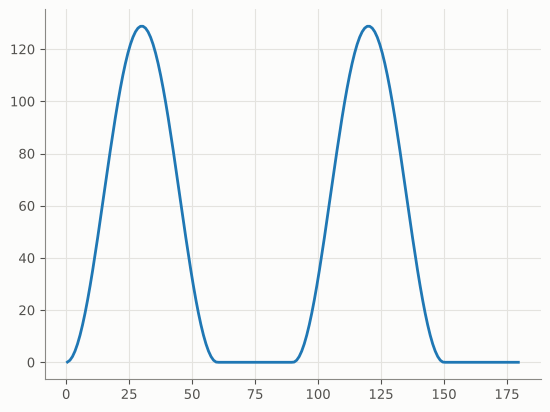

In [25]:
plt.plot(days2[:-1] + 0.5, 1e3 * melt_per_day2)

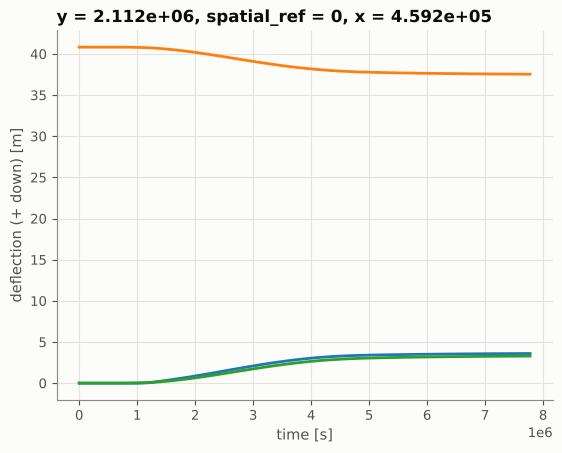

In [26]:
w_end = runs2["viscoelastic"].water_depth.isel(time=-1)
pt = w_end.isel(w_end.argmax(dim=["y", "x"]))
ts_at_max = coarse.sel(x=pt.x.item(), y=pt.y.item(), method="nearest")
ts_at_max.water_depth.plot()
ts_at_max.surface.plot()
ts_at_max.deflection.plot()

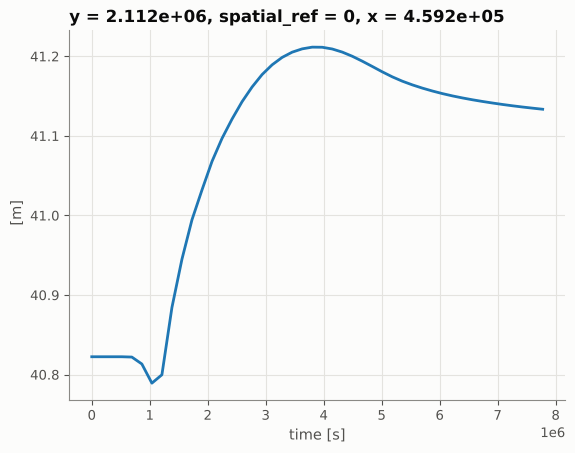

In [27]:
(ts_at_max.surface + ts_at_max.water_depth).plot()

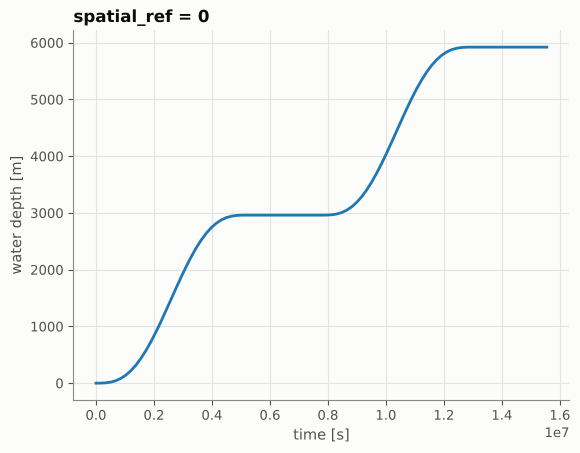

In [28]:
runs2["viscoelastic"].water_depth.sum(dim=["x", "y"]).plot()

In [29]:
ds = runs2["viscoelastic"].surface + runs2["viscoelastic"].water_depth
ds = ds-ds.isel(time=0)
ds.where(ds>0).hvplot(x = 'x',y='y', aspect='equal', width = 500)

:DynamicMap   [time]
   :Image   [x,y]   (value)

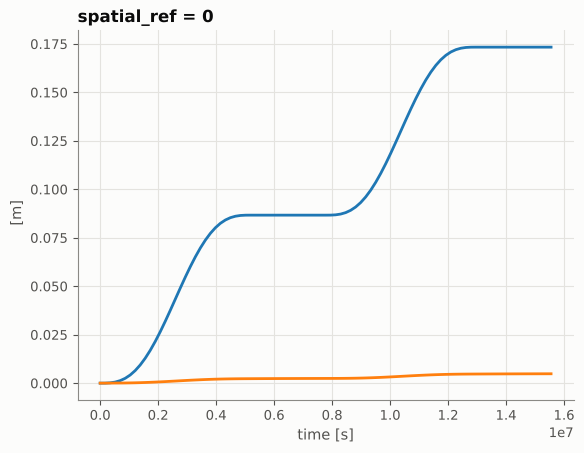

In [30]:
t_r = runs2['rigid'].surface + runs2['rigid'].water_depth
t_v = runs2['viscoelastic'].surface + runs2['viscoelastic'].water_depth

t_r = t_r - t_r.isel(time=0)
t_v = t_v - t_v.isel(time=0)

t_r.mean(dim=["x", "y"]).plot()
t_v.mean(dim=["x", "y"]).plot()

weights = t_r.fillna(0)
t_r_x = t_r.x.weighted(weights).mean(dim = ['x', 'y'])
t_r_y = t_r.y.weighted(weights).mean(dim = ['x', 'y'])

weights = t_v.fillna(0)
t_v_x = t_v.x.weighted(weights).mean(dim = ['x', 'y'])
t_v_y = t_v.y.weighted(weights).mean(dim = ['x', 'y'])

# plt.scatter(t_r_x, t_r_y, label = 'rigid',)
# plt.scatter(t_v_x, t_v_y, label = 'viscoelastic', )

(-0.00025, 0.00025)

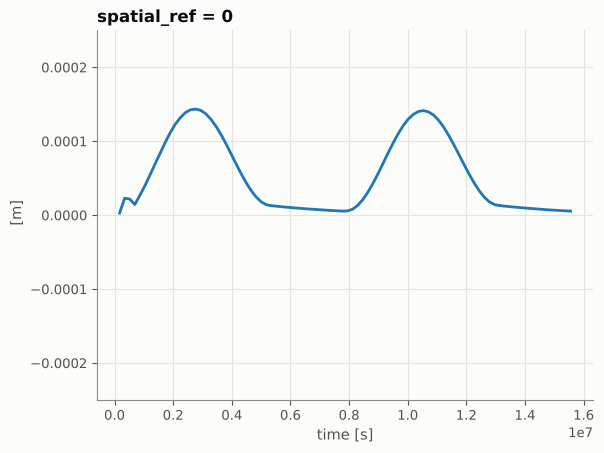

In [31]:
t_v.mean(dim=["x", "y"]).diff(dim='time').plot()
plt.ylim(-0.00025,0.00025)

In [32]:
t_r = runs2['rigid'].surface + runs2['rigid'].water_depth
t_v = runs2['viscoelastic'].surface + runs2['viscoelastic'].water_depth

# t_r = t_r - t_r.isel(time=0)
# t_v = t_v - t_v.isel(time=0)
t_v.sel(y=yc, method="nearest").sel(x=XS).hvplot(x='x', ylim=(10,50))* runs2['viscoelastic'].surface.sel(y=yc, method="nearest").sel(x=XS).hvplot(x='x')


:DynamicMap   [time]
   :Overlay
      .Curve.I  :Curve   [x]   (value)
      .Curve.II :Curve   [x]   (deformed surface (dem - w))

In [33]:
import inspect, lake_routing
print("fixed version loaded:", "settle" in inspect.getsource(lake_routing.route_with_flexure))

fixed version loaded: True


In [34]:
runs2['viscoelastic'].sel(y=yc, method="nearest").deflection.sel(x=XS).hvplot(x='x')

:DynamicMap   [time]
   :Curve   [x]   (deflection (+ down))

In [35]:
t =  np.arange(300)*DAY  # seconds
ds = route_with_flexure(dem = dem, 
                        melt = lambda i: circular_mask * 10,
                        times = t, 
                        plate=ShelfPlate(dem, floating, IceShelf(H=H, eta=1e14), coarsen=4).start(), 
                        substeps=16,
                        store=range(0, t.size, 12),
                        verbose = True)


  day   10.0: stored   5097.7 Mm3, lost   2746.1 Mm3, max deflection  54.27 m


  day   20.0: stored   9297.3 Mm3, lost   6390.4 Mm3, max deflection  91.17 m


  day   30.0: stored  13234.3 Mm3, lost  10297.3 Mm3, max deflection 119.45 m


  day   40.0: stored  17309.5 Mm3, lost  14065.9 Mm3, max deflection 143.52 m


  day   50.0: stored  20952.2 Mm3, lost  18267.0 Mm3, max deflection 163.16 m


  day   60.0: stored  23334.9 Mm3, lost  23728.2 Mm3, max deflection 176.41 m


... (19 outputs left out)

  day  260.0: stored  28335.6 Mm3, lost 175604.2 Mm3, max deflection 204.07 m


  day  270.0: stored  28336.5 Mm3, lost 183447.2 Mm3, max deflection 204.07 m


  day  280.0: stored  28337.0 Mm3, lost 191290.5 Mm3, max deflection 204.08 m


  day  290.0: stored  28337.5 Mm3, lost 199133.9 Mm3, max deflection 204.08 m


In [36]:
t =  np.arange(300)*DAY  # seconds
ds = route_with_flexure(dem = dem, 
                        melt = lambda i: dem * 0 + 0.1,
                        times = t, 
                        plate=ShelfPlate(dem, floating, IceShelf(H=H, eta=1e14), coarsen=4).start(), 
                        substeps=16,
                        store=range(0, t.size, 12),
                        verbose = True)


  day   10.0: stored   2527.7 Mm3, lost    970.7 Mm3, max deflection  36.47 m


  day   20.0: stored   4923.7 Mm3, lost   2073.1 Mm3, max deflection  63.87 m


  day   30.0: stored   7318.7 Mm3, lost   3176.4 Mm3, max deflection  85.85 m


  day   40.0: stored   9712.6 Mm3, lost   4281.0 Mm3, max deflection 104.33 m


  day   50.0: stored  12107.8 Mm3, lost   5384.2 Mm3, max deflection 120.49 m


  day   60.0: stored  14502.8 Mm3, lost   6487.6 Mm3, max deflection 134.91 m


... (19 outputs left out)

  day  260.0: stored  28507.5 Mm3, lost  62450.8 Mm3, max deflection 204.04 m


  day  270.0: stored  28510.2 Mm3, lost  65946.4 Mm3, max deflection 204.05 m


  day  280.0: stored  28512.2 Mm3, lost  69442.8 Mm3, max deflection 204.06 m


  day  290.0: stored  28513.6 Mm3, lost  72939.9 Mm3, max deflection 204.07 m


In [37]:
ds

<xarray.Dataset> Size: 10MB
Dimensions:         (time: 25, y: 219, x: 156, step_time: 300)
Coordinates:
  * time            (time) float64 200B 0.0 1.037e+06 ... 2.385e+07 2.488e+07
    time_days       (time) float64 200B 0.0 12.0 24.0 36.0 ... 264.0 276.0 288.0
  * y               (y) float64 2kB 2.13e+06 2.129e+06 ... 2.06e+06 2.06e+06
  * x               (x) float64 1kB 4.202e+05 4.205e+05 ... 4.694e+05 4.698e+05
  * step_time       (step_time) float64 2kB 0.0 8.64e+04 ... 2.575e+07 2.583e+07
    step_time_days  (step_time) float64 2kB 0.0 1.0 2.0 ... 297.0 298.0 299.0
    spatial_ref     int64 8B 0
Data variables:
    water_depth     (time, y, x) float32 3MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    deflection      (time, y, x) float32 3MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    surface         (time, y, x) float32 3MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    melt_added      (step_time) float64 2kB 0.0 3.498e+08 ... 1.046e+11
    water_stored    (step_time) float64 2kB 0.0 2.964e+08 ... 2.851e+10
    water_lost      (step_time) float64 2kB 0.0 5.339e+07 ... 7.609e+10
    max_deflection  (step_time) float64 2kB 0.0 3.986 8.097 ... 204.1 204.1
Attributes:
    coupled:      1
    substeps:     16
    ocean_level:  0.0
    shelf_H:      400.0
    shelf_E:      1000000000.0
    shelf_eta:    100000000000000.0
    shelf_nu:     0.3
    shelf_nu_v:   0.5
    plate_dx:     1280.0

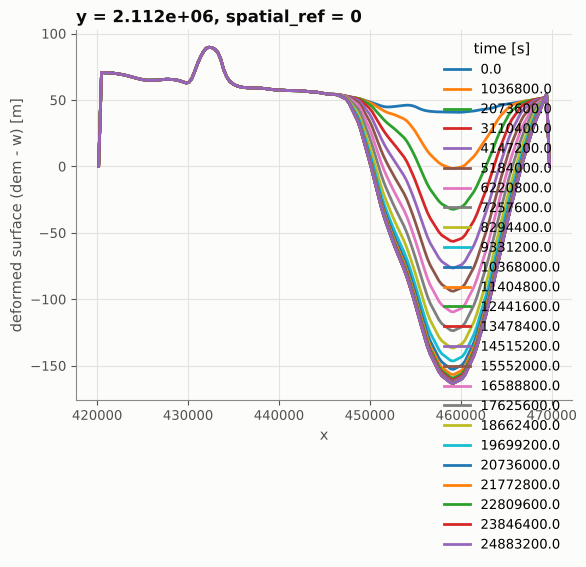

In [38]:
yc, xc = ds.isel(time=-1).water_depth.where(floating).stack(p=("y", "x")).idxmax("p").item()
XS = slice(xc - 8e4, xc + 8e4)
ds.surface.sel(y=yc, x=XS).plot.line(x = 'x');

In [39]:
hv(ds)

:Layout
   .DynamicMap.I  :DynamicMap   [time]
      :Overlay
         .Image.I  :Image   [x,y]   (water depth)
         .Image.II :Image   [x,y]   (water depth)
   .DynamicMap.II :DynamicMap   [time]
      :Image   [x,y]   (deflection (+ down))

In [40]:
dem2 = load_dem(DEM_FILE, coarsen=3)          # 64 m; the edge ring is an ocean outlet
dem2  = dem2.sel(x = slice(420000, 470000), y = slice( 2.13e6, 2.06e6,))
center_x = dem2.x.mean().values
center_y = dem2.y.mean().values-10000

region_size = 5000
circular_mask = (np.abs(dem2.x - center_x)**2 + (np.abs(dem2.y - center_y)**2) < region_size**2).transpose(*dem2.dims)

z = dem2.values.copy()
z[[0, -1], :] = z[:, [0, -1]] = 0.0
dem2 = dem2.copy(data=z)
floating = floating_mask(dem2)
area = lr.cell_area(dem2)
hs = hillshade(dem2)


t =  np.arange(100)*DAY  # seconds
ds = route_with_flexure(dem = dem2, 
                        melt = lambda i: circular_mask * 0.5,
                        times = t, 
                        plate=ShelfPlate(dem2, floating, IceShelf(H=H, eta=1e18), coarsen=4).start(), 
                        substeps=4,
                        store=range(0, t.size, 12),
                        verbose = True)




  day   10.0: stored    392.5 Mm3, lost      0.0 Mm3, max deflection  12.99 m


  day   20.0: stored    785.0 Mm3, lost     -0.0 Mm3, max deflection  22.31 m


  day   30.0: stored   1177.5 Mm3, lost     -0.0 Mm3, max deflection  30.28 m


  day   40.0: stored   1570.0 Mm3, lost     -0.0 Mm3, max deflection  37.37 m


  day   50.0: stored   1962.5 Mm3, lost     -0.0 Mm3, max deflection  43.89 m


  day   60.0: stored   2355.1 Mm3, lost     -0.0 Mm3, max deflection  50.01 m


  day   70.0: stored   2747.6 Mm3, lost     -0.0 Mm3, max deflection  55.83 m


  day   80.0: stored   3140.1 Mm3, lost     -0.0 Mm3, max deflection  61.38 m


  day   90.0: stored   3532.6 Mm3, lost     -0.0 Mm3, max deflection  66.70 m


In [41]:
ds.deflection.hvplot(x='x', y='y', aspect='equal', width = 500, cmap='RdBu_r', clim=(-.2,.2))

:DynamicMap   [time]
   :Image   [x,y]   (deflection (+ down))

In [42]:
hv(ds)

:Layout
   .DynamicMap.I  :DynamicMap   [time]
      :Overlay
         .Image.I  :Image   [x,y]   (water depth)
         .Image.II :Image   [x,y]   (water depth)
   .DynamicMap.II :DynamicMap   [time]
      :Image   [x,y]   (deflection (+ down))

## 7. Record the run

The coupled run is a single `xarray.Dataset`:

* maps of water depth, deflection and deformed surface every 10 days;
* the daily water budget;
* the shelf parameters, in `attrs`.

It is written to `outputs/` as compressed NetCDF.

In [43]:
def save(ds, name):
    enc = {v: {"zlib": True, "complevel": 4, **({"dtype": "float32"} if ds[v].dtype.kind == "f" else {})}
           for v in ds.data_vars}
    path = os.path.join(OUT_DIR, name)
    ds.to_netcdf(path, encoding=enc)
    print(f"{path}: {os.path.getsize(path) / 1e6:.1f} MB")

for name, r in runs.items():
    r.attrs.update(run=name, melt_m=MELT, season_days=SEASON, dem_file=DEM_FILE)
    save(r, f"coupled_routing_{name}.nc")

outputs/coupled_routing_rigid.nc: 4.2 MB


outputs/coupled_routing_elastic.nc: 7.6 MB


outputs/coupled_routing_viscoelastic.nc: 7.7 MB


## Summary

* **More water stays on the shelf.** Over a 60-day season with 0.5 m of melt, the viscoelastic shelf ends up holding 633 Mm³, against 586 Mm³ on a rigid shelf (+8%). Correspondingly less water leaves the domain. A purely elastic shelf holds only 596 Mm³, so most of the effect comes from viscous creep rather than the instantaneous sag.
* **Full lakes gain the most.** On the rigid shelf, several lakes out on the floating ice are full and spill downstream. On the flexing shelf they sag under their own water, so their basins deepen faster than their rims and they hold back water that would have spilled on. Three of them end up with 2–5 times as much water.
* **The grounding-line lake changes shape, not size.** It is not full on the rigid shelf: its volume is set by how much water reaches it, so it holds the same ~343 Mm³ either way. Coupled, though, it sinks into a deeper, narrower bowl. The ice beneath it sags by 31 m by the end of the melt and by up to ~40 m a month later. By day 90 the lake covers 21 km² instead of 49 km², its deepest point is 45 m instead of 31 m, and its water surface is 9 m lower.
* **Sag versus depth.** By the end of the run, the median sag under water on floating ice is about 60% of the isostatic $\rho_w d/\rho_{sw}$. Narrow lakes, and lakes within a few flexural lengths of the grounding line, are held up by the plate's stiffness.
* **After the melt stops** the shelf keeps creeping, but the water stays: deepening basins never push water out.
* **Numerics.** Coupling every 2 days instead of every day changes storage by at most 1.3%. Each coupled day costs about 0.8 s, so a season takes about a minute.
* **Outputs.** Each run is an `xarray.Dataset` with maps every 10 days and the daily water budget, saved to `outputs/coupled_routing_<run>.nc`.

**Caveats:** the DEM is taken to be the unloaded surface; uniform thickness and rheology; routing is instantaneous, with no slush or firn storage and no channel incision; grounded ice is fixed; uniform melt.